Importing libraries

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

Creating SparkSession

In [2]:
spark = SparkSession.builder \
    .appName("Goodbooks Logistic Regression") \
    .master("local[*]") \
    .getOrCreate()

spark

Loading the dataset using Spark

In [3]:
df_spark = spark.read.csv(
    "books.csv",
    header=True,
    inferSchema=True
)

Checking the data

In [4]:
df_spark.show(5)

+---+-------+------------+-------+-----------+---------+----------------+--------------------+-------------------------+--------------------+--------------------+-------------+--------------+-------------+------------------+-----------------------+---------+---------+---------+---------+---------+--------------------+--------------------+
| id|book_id|best_book_id|work_id|books_count|     isbn|          isbn13|             authors|original_publication_year|      original_title|               title|language_code|average_rating|ratings_count|work_ratings_count|work_text_reviews_count|ratings_1|ratings_2|ratings_3|ratings_4|ratings_5|           image_url|     small_image_url|
+---+-------+------------+-------+-----------+---------+----------------+--------------------+-------------------------+--------------------+--------------------+-------------+--------------+-------------+------------------+-----------------------+---------+---------+---------+---------+---------+--------------------

Checking the number of records

In [5]:
print("Number of records:", df_spark.count())
print("Number of columns:", len(df_spark.columns))

Number of records: 10000
Number of columns: 23


Displaying the Spark schema

In [6]:
df_spark.printSchema()

root
 |-- id: integer (nullable = true)
 |-- book_id: integer (nullable = true)
 |-- best_book_id: integer (nullable = true)
 |-- work_id: integer (nullable = true)
 |-- books_count: integer (nullable = true)
 |-- isbn: string (nullable = true)
 |-- isbn13: double (nullable = true)
 |-- authors: string (nullable = true)
 |-- original_publication_year: double (nullable = true)
 |-- original_title: string (nullable = true)
 |-- title: string (nullable = true)
 |-- language_code: string (nullable = true)
 |-- average_rating: string (nullable = true)
 |-- ratings_count: string (nullable = true)
 |-- work_ratings_count: string (nullable = true)
 |-- work_text_reviews_count: string (nullable = true)
 |-- ratings_1: double (nullable = true)
 |-- ratings_2: integer (nullable = true)
 |-- ratings_3: integer (nullable = true)
 |-- ratings_4: integer (nullable = true)
 |-- ratings_5: integer (nullable = true)
 |-- image_url: string (nullable = true)
 |-- small_image_url: string (nullable = true)


In [7]:
numeric_features = [
    "average_rating",
    "ratings_count",
    "work_ratings_count",
    "work_text_reviews_count"
]

In [8]:
df_spark = df_spark.withColumn(
    "work_ratings_count",
    F.col("work_ratings_count").cast("long")
)

df_spark = df_spark.withColumn(
    "work_text_reviews_count",
    F.col("work_text_reviews_count").cast("long")
)

In [9]:

numeric_features = [
    "average_rating",
    "ratings_count",
    "work_ratings_count",
    "work_text_reviews_count"
]

for feature in numeric_features:
    df_spark = df_spark.withColumn(
        feature,
        F.col(feature).cast("double")
    )

In [10]:
df_spark.printSchema()

root
 |-- id: integer (nullable = true)
 |-- book_id: integer (nullable = true)
 |-- best_book_id: integer (nullable = true)
 |-- work_id: integer (nullable = true)
 |-- books_count: integer (nullable = true)
 |-- isbn: string (nullable = true)
 |-- isbn13: double (nullable = true)
 |-- authors: string (nullable = true)
 |-- original_publication_year: double (nullable = true)
 |-- original_title: string (nullable = true)
 |-- title: string (nullable = true)
 |-- language_code: string (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- ratings_count: double (nullable = true)
 |-- work_ratings_count: double (nullable = true)
 |-- work_text_reviews_count: double (nullable = true)
 |-- ratings_1: double (nullable = true)
 |-- ratings_2: integer (nullable = true)
 |-- ratings_3: integer (nullable = true)
 |-- ratings_4: integer (nullable = true)
 |-- ratings_5: integer (nullable = true)
 |-- image_url: string (nullable = true)
 |-- small_image_url: string (nullable = true)


Spark descriptive statistics

In [11]:
df_spark.describe().show()

+-------+------------------+-----------------+----------------+-------------------+-----------------+-------------------+--------------------+--------------------+-------------------------+--------------+-----------------------------------+--------------------+------------------+-----------------+------------------+-----------------------+-----------------+-----------------+-----------------+------------------+-----------------+--------------------+--------------------+
|summary|                id|          book_id|    best_book_id|            work_id|      books_count|               isbn|              isbn13|             authors|original_publication_year|original_title|                              title|       language_code|    average_rating|    ratings_count|work_ratings_count|work_text_reviews_count|        ratings_1|        ratings_2|        ratings_3|         ratings_4|        ratings_5|           image_url|     small_image_url|
+-------+------------------+-----------------+----

In [12]:
df_spark.select(
    "average_rating",
    "ratings_count",
    "work_ratings_count",
    "work_text_reviews_count"
).describe().show()

+-------+------------------+-----------------+------------------+-----------------------+
|summary|    average_rating|    ratings_count|work_ratings_count|work_text_reviews_count|
+-------+------------------+-----------------+------------------+-----------------------+
|  count|              9998|             9999|              9999|                   9999|
|   mean|4.0021624324864975|54003.90110111011| 59692.25862586259|      2922.014901490149|
| stddev|0.2544444289254295|157377.7001999715|167811.44396015457|      6127.088904232268|
|    min|              2.47|             4.11|            5510.0|                    3.0|
|    max|              4.82|        4780653.0|         4942365.0|               155254.0|
+-------+------------------+-----------------+------------------+-----------------------+



Checking missing values using Spark

In [13]:
missing_counts = []

for c in df_spark.columns:
    count = df_spark.filter(F.col(c).isNull()).count()
    missing_counts.append((c, count))

missing_summary = spark.createDataFrame(
    missing_counts,
    ["Column", "Missing_Values"]
)

missing_summary.orderBy(
    F.desc("Missing_Values")
).show(truncate=False)

+-------------------------+--------------+
|Column                   |Missing_Values|
+-------------------------+--------------+
|language_code            |1084          |
|isbn                     |700           |
|isbn13                   |585           |
|original_title           |585           |
|original_publication_year|21            |
|average_rating           |2             |
|work_ratings_count       |1             |
|ratings_count            |1             |
|work_text_reviews_count  |1             |
|authors                  |0             |
|title                    |0             |
|best_book_id             |0             |
|ratings_5                |0             |
|work_id                  |0             |
|ratings_3                |0             |
|books_count              |0             |
|image_url                |0             |
|ratings_1                |0             |
|small_image_url          |0             |
|id                       |0             |
+----------

Dropping the unnecessary columns

In [14]:
df_spark = df_spark.drop(
    "isbn",
    "isbn13",
    "original_title",
    "language_code"
)

Checking duplicate records using Spark

In [15]:
duplicate_count = (
    df_spark.groupBy(df_spark.columns)
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Duplicate records:", duplicate_count)

Duplicate records: 0


SPARK EDA VISUALISATIONS

Average rating distribution using Spark

In [16]:
rating_distribution = (
    df_spark
    .groupBy("average_rating")
    .count()
    .orderBy("average_rating")
)

rating_distribution.show(20)

+--------------+-----+
|average_rating|count|
+--------------+-----+
|          NULL|    2|
|          2.47|    1|
|          2.67|    1|
|          2.76|    1|
|           2.8|    2|
|          2.84|    3|
|          2.93|    2|
|          2.96|    1|
|          2.97|    1|
|          2.98|    1|
|           3.0|    1|
|          3.01|    1|
|          3.02|    1|
|          3.04|    2|
|          3.05|    1|
|          3.07|    2|
|          3.08|    2|
|          3.09|    1|
|           3.1|    3|
|          3.11|    1|
+--------------+-----+
only showing top 20 rows



Converting the aggregated result to Pandas

In [17]:
rating_pd = rating_distribution.toPandas()

Plot

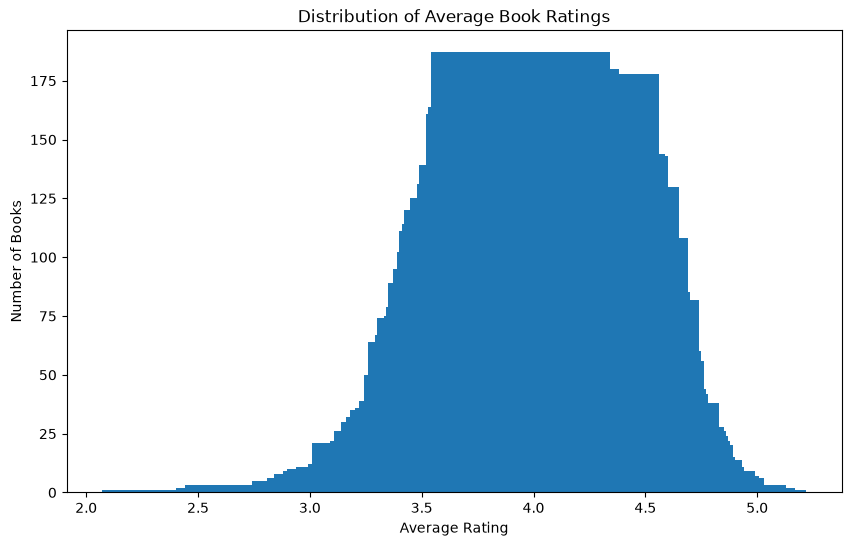

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.bar(
    rating_pd["average_rating"],
    rating_pd["count"]
)

plt.title("Distribution of Average Book Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Books")

plt.show()

Analysing ratings count using Spark

In [19]:
df_spark.select("ratings_count").summary().show()

+-------+-----------------+
|summary|    ratings_count|
+-------+-----------------+
|  count|             9999|
|   mean|54003.90110111011|
| stddev|157377.7001999715|
|    min|             4.11|
|    25%|          13566.0|
|    50%|          21154.0|
|    75%|          41052.0|
|    max|        4780653.0|
+-------+-----------------+



Creating a logarithmic variable

In [20]:
df_spark = df_spark.withColumn(
    "log_ratings_count",
    F.log1p(F.col("ratings_count"))
)

In [21]:
df_spark.select(
    "ratings_count",
    "log_ratings_count"
).show(10)

+-------------+------------------+
|ratings_count| log_ratings_count|
+-------------+------------------+
|    4780653.0|15.380087915192307|
|    4602479.0|15.342105846615507|
|    3866839.0|15.167948193989965|
|    3198671.0|14.978246281633623|
|    2683664.0| 14.80269395557295|
|    2346404.0|14.668394927567077|
|    2071616.0|14.543840019715619|
|    2044241.0|14.530537618600889|
|    2001311.0|14.509313523450274|
|    2035490.0| 14.52624762539734|
+-------------+------------------+
only showing top 10 rows



CREATING THE TARGET VARIABLE USING SPARK

Calculating the 80% using Spark

In [22]:
threshold = df_spark.approxQuantile(
    "ratings_count",
    [0.80],
    0.01
)[0]

print("Bestseller threshold:", threshold)

Bestseller threshold: 48695.0


Creating the bestseller variable using Spark

In [23]:
df_spark = df_spark.withColumn(
    "bestseller",
    F.when(
        F.col("ratings_count") >= threshold,
        1
    ).otherwise(0)
)

In [24]:
df_spark.groupBy("bestseller").count().show()

+----------+-----+
|bestseller|count|
+----------+-----+
|         1| 2059|
|         0| 7941|
+----------+-----+



Checking percentages

In [25]:
df_spark.groupBy("bestseller").count() \
    .withColumn(
        "percentage",
        F.col("count") / df_spark.count() * 100
    ) \
    .show()

+----------+-----+----------+
|bestseller|count|percentage|
+----------+-----+----------+
|         1| 2059|     20.59|
|         0| 7941|     79.41|
+----------+-----+----------+



Boxplot - Average rating vs bestseller-proxy status

<Figure size 800x500 with 0 Axes>

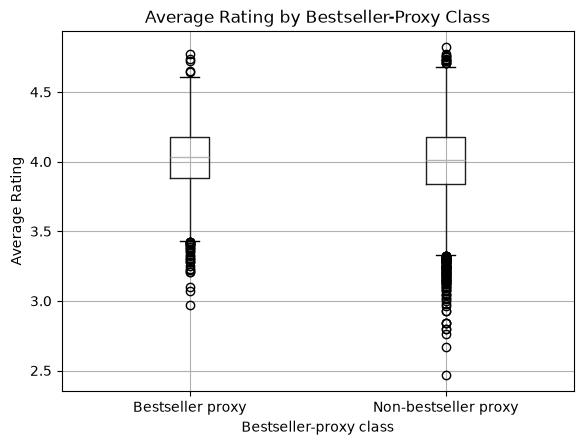

In [26]:
rating_class_pd = df_spark.select(
    "average_rating",
    "bestseller"
).dropna().toPandas()

rating_class_pd["Class"] = rating_class_pd["bestseller"].map({
    0: "Non-bestseller proxy",
    1: "Bestseller proxy"
})

plt.figure(figsize=(8,5))

rating_class_pd.boxplot(
    column="average_rating",
    by="Class"
)

plt.title("Average Rating by Bestseller-Proxy Class")
plt.suptitle("")
plt.xlabel("Bestseller-proxy class")
plt.ylabel("Average Rating")
plt.show()

FEATURE SELECTION USING SPARK

Calculating correlations using Spark

In [27]:
numeric_features = [
    "books_count",
    "original_publication_year",
    "average_rating"
]

In [28]:
for feature in numeric_features:
    correlation = df_spark.stat.corr(
        feature,
        "bestseller"
    )
    
    print(
        feature,
        "correlation with bestseller:",
        correlation
    )

books_count correlation with bestseller: 0.26750423313483745
original_publication_year correlation with bestseller: -0.018024905195150636
average_rating correlation with bestseller: 0.043436285837213845


PREPARE FEATURES USING SPARK

Creating author frequency using Spark

In [29]:
author_frequency = (
    df_spark
    .groupBy("authors")
    .count()
    .withColumnRenamed("count", "author_book_count")
)

In [30]:
df_spark = df_spark.join(
    author_frequency,
    on="authors",
    how="left"
)

CONVERTING SPARK DATA TO NUMPY FOR LOGISTIC REGRESSION

Selecting the final features

In [31]:
selected_columns = [
    "books_count",
    "original_publication_year",
    "average_rating",
    "author_book_count",
    "bestseller"
]

In [32]:
model_spark = df_spark.select(
    selected_columns
).dropna()

In [33]:
model_pd = model_spark.toPandas()

Create Spark DataFrame

In [34]:
df_spark.columns

['authors',
 'id',
 'book_id',
 'best_book_id',
 'work_id',
 'books_count',
 'original_publication_year',
 'title',
 'average_rating',
 'ratings_count',
 'work_ratings_count',
 'work_text_reviews_count',
 'ratings_1',
 'ratings_2',
 'ratings_3',
 'ratings_4',
 'ratings_5',
 'image_url',
 'small_image_url',
 'log_ratings_count',
 'bestseller',
 'author_book_count']

Converting to Pandas

In [35]:
model_pd = model_spark.toPandas()

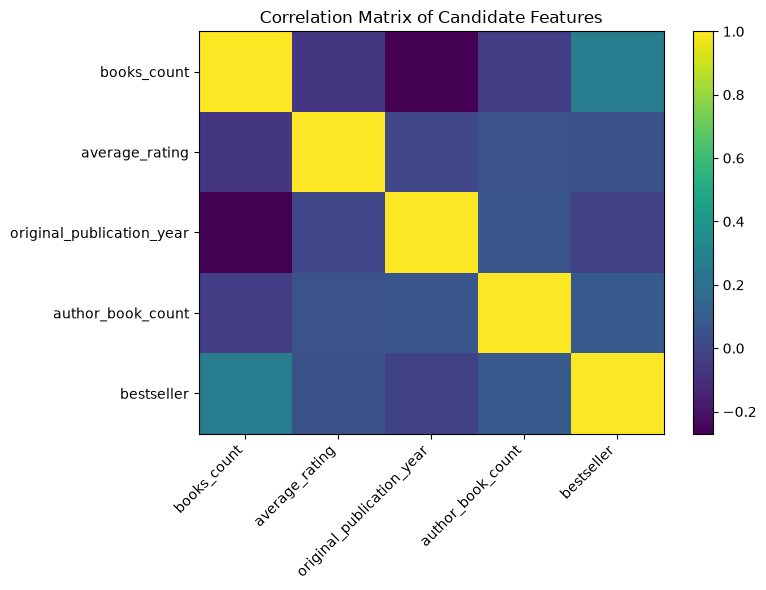

In [36]:
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt

corr_columns = [
    "books_count",
    "average_rating",
    "original_publication_year",
    "author_book_count",
    "bestseller"
]

corr_matrix = []

for col1 in corr_columns:
    row = []
    for col2 in corr_columns:
        row.append(
            df_spark.stat.corr(col1, col2)
        )
    corr_matrix.append(row)

corr_pd = pd.DataFrame(
    corr_matrix,
    index=corr_columns,
    columns=corr_columns
)

plt.figure(figsize=(8,6))
plt.imshow(corr_pd, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(corr_columns)),
    corr_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr_columns)),
    corr_columns
)

plt.title("Correlation Matrix of Candidate Features")
plt.tight_layout()
plt.show()

Separating predictors and target

In [37]:
X = model_pd[
    [
        "books_count",
        "original_publication_year",
        "average_rating",
        "author_book_count"
    ]
].values

y = model_pd["bestseller"].values

TRAIN/TEST SPLIT

In [38]:
import numpy as np

np.random.seed(42)

indices = np.arange(len(X))

np.random.shuffle(indices)

split_point = int(0.80 * len(indices))

train_indices = indices[:split_point]
test_indices = indices[split_point:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

STANDARDISING THE FEATURES

In [39]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

std[std == 0] = 1

X_train_scaled = (
    X_train - mean
) / std

X_test_scaled = (
    X_test - mean
) / std

Adding intercept

In [40]:
X_train_scaled = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

X_test_scaled = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

LOGISTIC REGRESSION FROM SCRATCH

In [41]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

Training algorithm

In [42]:
def train_logistic_regression(
    X,
    y,
    learning_rate=0.05,
    epochs=5000
):
    
    weights = np.zeros(X.shape[1])
    
    for epoch in range(epochs):
        
        z = np.dot(X, weights)
        
        predictions = sigmoid(z)
        
        gradient = np.dot(
            X.T,
            predictions - y
        ) / len(y)
        
        weights = (
            weights -
            learning_rate * gradient
        )
    
    return weights

In [43]:
weights = train_logistic_regression(
    X_train_scaled,
    y_train,
    learning_rate=0.05,
    epochs=5000
)

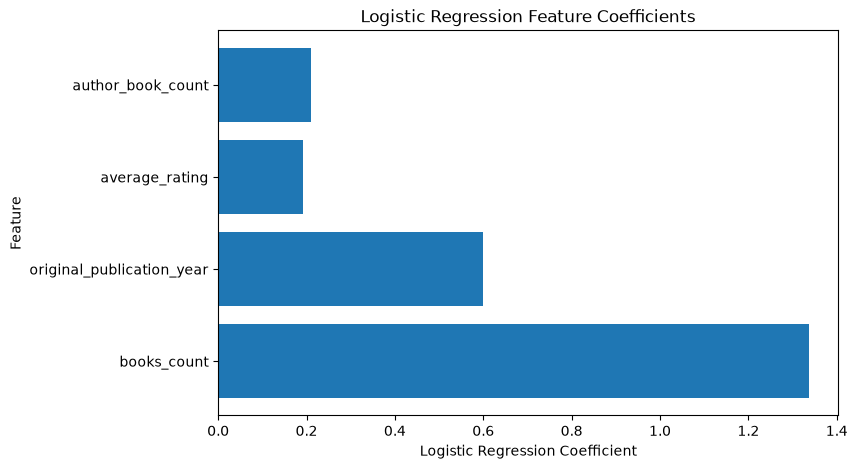

In [44]:
feature_names = [
    "books_count",
    "original_publication_year",
    "average_rating",
    "author_book_count"
]

coefficients = weights[1:]

plt.figure(figsize=(8,5))

plt.barh(feature_names, coefficients)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Logistic Regression Feature Coefficients")

plt.show()

GENERATING PREDICTIONS

In [45]:
probabilities = sigmoid(
    np.dot(
        X_test_scaled,
        weights
    )
)

predictions = (
    probabilities >= 0.50
).astype(int)

MODEL EVALUATION USING SPARK

In [46]:
import pandas as pd

results = pd.DataFrame({
    "actual": y_test,
    "predicted": predictions,
    "probability": probabilities
})

results_spark = spark.createDataFrame(results)

results_spark.show(10)

+------+---------+-------------------+
|actual|predicted|        probability|
+------+---------+-------------------+
|     0|        0|0.14785177320683668|
|     0|        0|0.20663640140705627|
|     0|        0|0.15095658618649502|
|     0|        0|0.22172735916221445|
|     0|        0| 0.1818672030679004|
|     0|        0| 0.1497939021369179|
|     0|        0|0.18175480857931064|
|     1|        1| 0.8038575070546932|
|     0|        0|0.16846156893856004|
|     0|        0|0.17970332811192133|
+------+---------+-------------------+
only showing top 10 rows



CONFUSION MATRIX USING SPARK

In [47]:
results_spark.groupBy(
    "actual",
    "predicted"
).count().orderBy(
    "actual",
    "predicted"
).show()

+------+---------+-----+
|actual|predicted|count|
+------+---------+-----+
|     0|        0| 1565|
|     0|        1|   25|
|     1|        0|  366|
|     1|        1|   40|
+------+---------+-----+



In [48]:
TP = results_spark.filter(
    (F.col("actual") == 1) &
    (F.col("predicted") == 1)
).count()

TN = results_spark.filter(
    (F.col("actual") == 0) &
    (F.col("predicted") == 0)
).count()

FP = results_spark.filter(
    (F.col("actual") == 0) &
    (F.col("predicted") == 1)
).count()

FN = results_spark.filter(
    (F.col("actual") == 1) &
    (F.col("predicted") == 0)
).count()

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

TP: 40
TN: 1565
FP: 25
FN: 366


CALCULATING METRICS

In [49]:
accuracy = (
    (TP + TN) /
    (TP + TN + FP + FN)
)

precision = (
    TP /
    (TP + FP)
    if (TP + FP) > 0 else 0
)

recall = (
    TP /
    (TP + FN)
    if (TP + FN) > 0 else 0
)

f1 = (
    2 * precision * recall /
    (precision + recall)
    if (precision + recall) > 0 else 0
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.8041082164328658
Precision: 0.6153846153846154
Recall   : 0.09852216748768473
F1 Score : 0.16985138004246284


RETRAINING WITH DIFFERENT PARAMETERS

In [50]:
def train_weighted_logistic_regression(
    X,
    y,
    learning_rate=0.05,
    epochs=5000,
    positive_weight=4
):
    
    weights = np.zeros(X.shape[1])
    
    sample_weights = np.where(
        y == 1,
        positive_weight,
        1
    )
    
    for epoch in range(epochs):
        
        z = np.dot(X, weights)
        
        predictions = sigmoid(z)
        
        gradient = np.dot(
            X.T,
            sample_weights *
            (predictions - y)
        ) / np.sum(sample_weights)
        
        0
            weights -
            learning_rate * gradient
        )
    
    return weights

Training model

In [51]:
weighted_weights = train_weighted_logistic_regression(
    X_train_scaled,
    y_train,
    learning_rate=0.05,
    epochs=5000,
    positive_weight=4
)

Prediction

In [52]:
weighted_probabilities = sigmoid(
    np.dot(
        X_test_scaled,
        weighted_weights
    )
)

weighted_predictions = (
    weighted_probabilities >= 0.50
).astype(int)

EVALUATING THE RETRAINED MODEL USING SPARK

In [53]:
results2 = pd.DataFrame({
    "actual": y_test,
    "predicted": weighted_predictions,
    "probability": weighted_probabilities
})

results2_spark = spark.createDataFrame(results2)

Confusion matrix

In [54]:
results2_spark.groupBy(
    "actual",
    "predicted"
).count().orderBy(
    "actual",
    "predicted"
).show()

+------+---------+-----+
|actual|predicted|count|
+------+---------+-----+
|     0|        0| 1266|
|     0|        1|  324|
|     1|        0|  169|
|     1|        1|  237|
+------+---------+-----+



In [55]:
TP2 = results2_spark.filter(
    (F.col("actual") == 1) &
    (F.col("predicted") == 1)
).count()

TN2 = results2_spark.filter(
    (F.col("actual") == 0) &
    (F.col("predicted") == 0)
).count()

FP2 = results2_spark.filter(
    (F.col("actual") == 0) &
    (F.col("predicted") == 1)
).count()

FN2 = results2_spark.filter(
    (F.col("actual") == 1) &
    (F.col("predicted") == 0)
).count()

Metrics

In [56]:
accuracy2 = (
    (TP2 + TN2) /
    (TP2 + TN2 + FP2 + FN2)
)

precision2 = (
    TP2 /
    (TP2 + FP2)
    if (TP2 + FP2) > 0 else 0
)

recall2 = (
    TP2 /
    (TP2 + FN2)
    if (TP2 + FN2) > 0 else 0
)

f1_2 = (
    2 * precision2 * recall2 /
    (precision2 + recall2)
    if (precision2 + recall2) > 0 else 0
)

print("Retrained Accuracy :", accuracy2)
print("Retrained Precision:", precision2)
print("Retrained Recall   :", recall2)
print("Retrained F1 Score :", f1_2)

Retrained Accuracy : 0.753006012024048
Retrained Precision: 0.42245989304812837
Retrained Recall   : 0.583743842364532
Retrained F1 Score : 0.49017580144777667


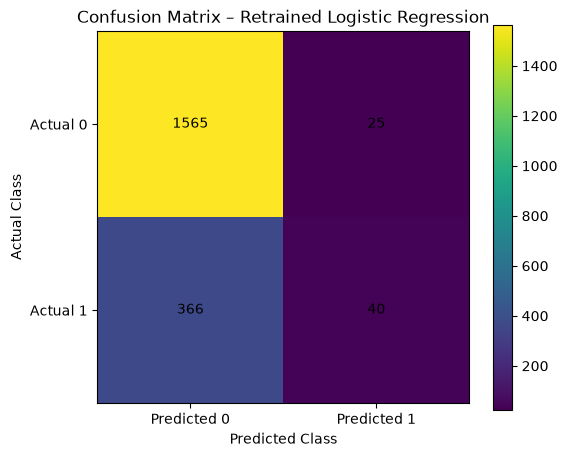

In [57]:
import matplotlib.pyplot as plt

cm = np.array([
    [TN, FP],
    [FN, TP]
])

plt.figure(figsize=(6,5))
plt.imshow(cm)

plt.colorbar()

plt.xticks([0,1], ["Predicted 0", "Predicted 1"])
plt.yticks([0,1], ["Actual 0", "Actual 1"])

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix – Retrained Logistic Regression")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j],
                 ha="center",
                 va="center")

plt.show()

COMPARING THE TWO MODELS

In [58]:
comparison = spark.createDataFrame([
    ("Original", accuracy, precision, recall, f1),
    ("Retrained", accuracy2, precision2, recall2, f1_2)
], [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
])

comparison.show()

+---------+------------------+-------------------+-------------------+-------------------+
|    Model|          Accuracy|          Precision|             Recall|                 F1|
+---------+------------------+-------------------+-------------------+-------------------+
| Original|0.8041082164328658| 0.6153846153846154|0.09852216748768473|0.16985138004246284|
|Retrained| 0.753006012024048|0.42245989304812837|  0.583743842364532|0.49017580144777667|
+---------+------------------+-------------------+-------------------+-------------------+



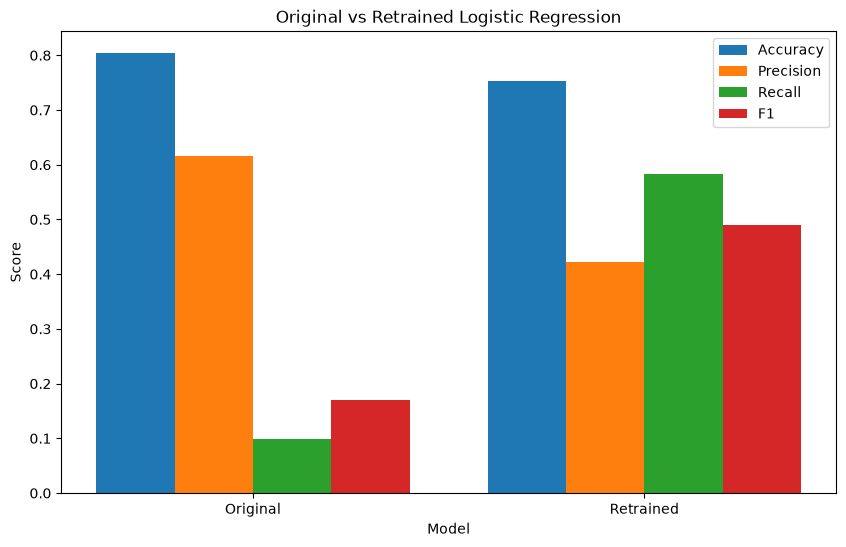

In [59]:
models = ["Original", "Retrained"]

accuracy_values = [accuracy, accuracy2]
precision_values = [precision, precision2]
recall_values = [recall, recall2]
f1_values = [f1, f1_2]

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(10,6))

plt.bar(x - 1.5*width, accuracy_values, width, label="Accuracy")
plt.bar(x - 0.5*width, precision_values, width, label="Precision")
plt.bar(x + 0.5*width, recall_values, width, label="Recall")
plt.bar(x + 1.5*width, f1_values, width, label="F1")

plt.xticks(x, models)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Original vs Retrained Logistic Regression")
plt.legend()
plt.show()